#  Crop Yield Prediction Under Climate Change
### Predicting district-level wheat yield in Pakistan using machine learning

**Goal:** Build and compare models that predict wheat yield (tonnes per hectare) from climate conditions (temperature, rainfall, soil moisture), so farmers and decision-makers can plan better.

**Data sources**
1. Pakistan Bureau of Statistics: district-wise wheat area, production and yield
2. ERA5-Land (Copernicus): temperature, rainfall and soil moisture on a ~9 km grid
3. GADM: district boundaries, used to link climate grid squares to districts

**Notebook outline**
1. Load and inspect  →  2. Clean  →  3. Preprocess  →  4. Climate zones (K-Means)  →  5. Train models  →  6. Evaluate and compare  →  7. Export for the dashboard

## 1. Setup and Loading Data
Import our tools and load the merged table.
Every later step depends on this one table: one row per district per wheat season (Nov to Apr), with yield and climate side by side.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None) 

In [2]:
df = pd.read_csv("../data/wheat_climate_merged.csv", dtype={"district_code": str})

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (3654, 14)


,district_code,district,province,crop,fy,area_000ha,production_000t,yield_t_per_ha,season,temp_mean_c,rain_total_mm,soil_moist_l1,soil_moist_l2,temp_marapr_c
0,001,BANNU DISTRICT,KHYBER PAKHTUNKHWA,Wheat,1981-82,147.600006,145.600006,0.986450,1981,13.890351,238.021628,0.228435,0.240814,18.047710
1,003,DERA ISMAIL KHAN DISTRICT,KHYBER PAKHTUNKHWA,Wheat,1981-82,111.400002,148.699997,1.334829,1981,15.924747,226.646329,0.148884,0.211547,20.056334
2,005,ABBOTTABAD DISTRICT,KHYBER PAKHTUNKHWA,Wheat,1981-82,47.500000,62.700001,1.320000,1981,7.557691,794.794315,0.374045,0.373569,11.497916
3,009,MANSEHRA DISTRICT,KHYBER PAKHTUNKHWA,Wheat,1981-82,36.000000,42.299999,1.175000,1981,-1.578983,747.068780,0.340110,0.342363,2.655211
4,017,MALAKAND PROTECTED AREA,KHYBER PAKHTUNKHWA,Wheat,1981-82,26.900000,52.500000,1.951673,1981,10.861648,350.765246,0.274477,0.256994,15.249592


## 2. First Look at the Data
Check column types, summary numbers, missing values and duplicates.
We want to know what we have before changing anything.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3654 entries, 0 to 3653
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   district_code    3654 non-null   str    
 1   district         3654 non-null   str    
 2   province         3654 non-null   str    
 3   crop             3654 non-null   str    
 4   fy               3654 non-null   str    
 5   area_000ha       3654 non-null   float64
 6   production_000t  3654 non-null   float64
 7   yield_t_per_ha   3654 non-null   float64
 8   season           3654 non-null   int64  
 9   temp_mean_c      3654 non-null   float64
 10  rain_total_mm    3654 non-null   float64
 11  soil_moist_l1    3654 non-null   float64
 12  soil_moist_l2    3654 non-null   float64
 13  temp_marapr_c    3654 non-null   float64
dtypes: float64(8), int64(1), str(5)
memory usage: 551.0 KB


In [4]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
area_000ha,3654.0,85.30,88.34,0.10,13.24,46.98,142.49,469.40
production_000t,3654.0,204.28,246.76,0.05,20.69,89.95,340.45,1724.16
yield_t_per_ha,3654.0,2.06,0.81,0.25,1.43,1.96,2.61,4.75
season,3654.0,2003.84,13.13,1981.00,1993.00,2002.00,2016.00,2024.00
temp_mean_c,3654.0,16.16,5.52,-5.51,13.20,17.20,20.41,24.21
rain_total_mm,3654.0,190.12,199.80,0.35,39.63,119.59,281.69,1196.50
soil_moist_l1,3654.0,0.16,0.09,0.00,0.08,0.14,0.23,0.42
soil_moist_l2,3654.0,0.19,0.07,0.01,0.14,0.16,0.24,0.42
temp_marapr_c,3654.0,21.34,6.06,-1.63,17.80,22.62,26.09,31.16


In [5]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Districts:", df["district"].nunique())
print("Seasons:", df["season"].min(), "to", df["season"].max())
print()
print(df["province"].value_counts())

Missing values: 0
Duplicate rows: 0
Districts: 108
Seasons: 1981 to 2024

province
PUNJAB                         1226
KHYBER PAKHTUNKHWA              936
BALOCHISTAN                     821
SINDH                           632
ISLAMABAD CAPITAL TERRITORY      39
Name: count, dtype: int64


## 3. Data Cleaning
Check that the numbers make sense, then remove or fix problem rows.
A model learns whatever we feed it, including mistakes. A few silly rows can quietly spoil every score.

We run three checks:
1. Does `production ÷ area` really equal `yield`? (tells us which columns are safe to use)
2. Are there rows with a tiny wheat area? (tiny areas give unreliable yields)
3. Are there suspicious year-to-year jumps?

In [6]:
calculated = df["production_000t"] / df["area_000ha"]
difference = (calculated - df["yield_t_per_ha"]).abs()

print("Largest difference:", difference.max())
print("Rows that disagree:", (difference > 0.01).sum())

Largest difference: 6.045122757925014e-07
Rows that disagree: 0


**Finding:** The difference is essentially zero, so `production` is just `yield × area`. If we gave production to the model, it would be like handing it the answer sheet (called *data leakage*), so we will exclude it from the inputs later.

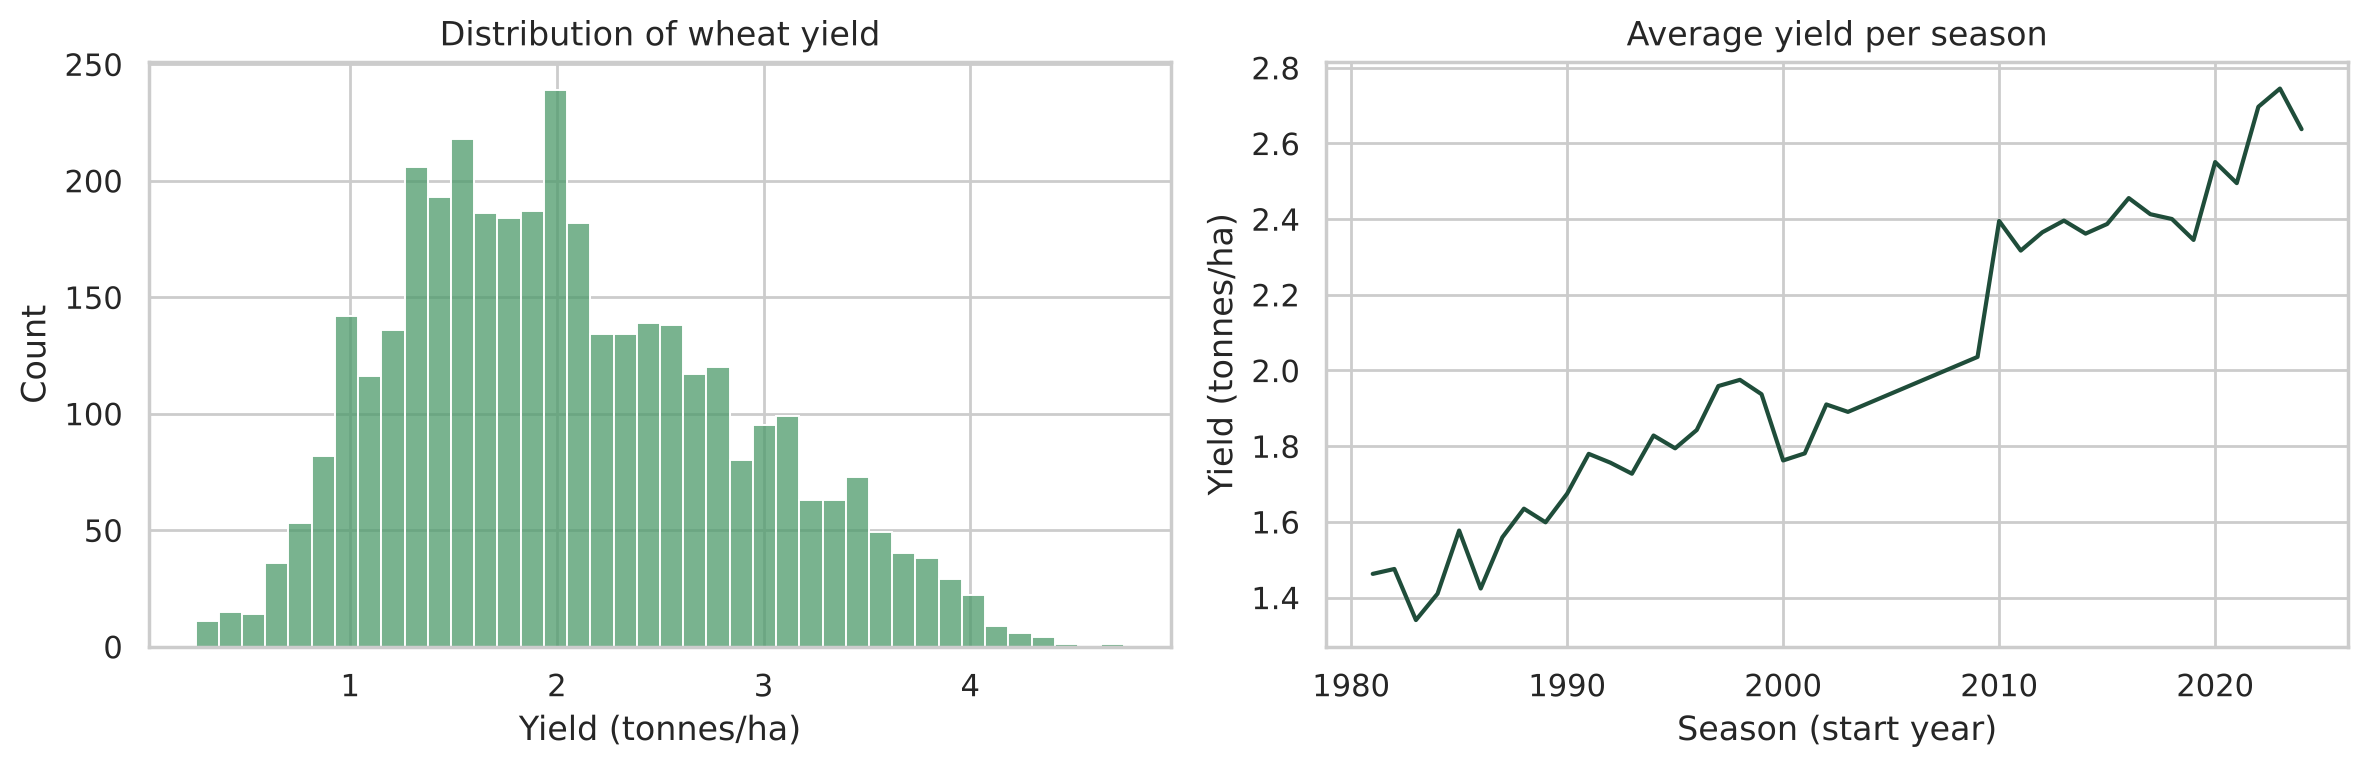

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["yield_t_per_ha"], bins=40, ax=ax[0], color="#4C9A6A")
ax[0].set_title("Distribution of wheat yield")
ax[0].set_xlabel("Yield (tonnes/ha)")

df.groupby("season")["yield_t_per_ha"].mean().plot(ax=ax[1], color="#1F4D3A")
ax[1].set_title("Average yield per season")
ax[1].set_xlabel("Season (start year)")
ax[1].set_ylabel("Yield (tonnes/ha)")

plt.tight_layout()
plt.show()

In [8]:
tiny = df[df["area_000ha"] < 0.5]

print("Rows with area under 500 hectares:", len(tiny))
print()
print(tiny["district"].value_counts().head(5))

Rows with area under 500 hectares: 63

district
KARACHI CENTRAL DISTRICT    23
GWADAR DISTRICT             15
ZIARAT DISTRICT             14
PANJGUR DISTRICT             3
LASBELA DISTRICT             3
Name: count, dtype: int64


In [9]:
check = df.sort_values(["district", "season"]).copy()
check["change"] = check.groupby("district")["yield_t_per_ha"].pct_change()

print("Rows where yield more than doubled or halved:", (check["change"].abs() > 1).sum())
check.loc[check["change"].abs() > 1.5,
          ["district", "fy", "yield_t_per_ha", "change"]].head(10)

Rows where yield more than doubled or halved: 22


,district,fy,yield_t_per_ha,change
530,CHAKWAL DISTRICT,1988-89,0.921186,2.048175
3413,GWADAR DISTRICT,2022-23,2.175355,7.068585
3627,GWADAR DISTRICT,2024-25,1.938202,1.803807
2138,KHUZDAR DISTRICT,2010-11,2.046569,1.586743
2147,KILLA ABDULLAH DISTRICT,2010-11,1.680851,1.570812
2155,KILLA SAIFULLAH DISTRICT,2010-11,1.735632,1.574919
121,KOHLU DISTRICT,1982-83,1.691358,1.688827
2153,ZIARAT DISTRICT,2010-11,1.333333,4.066663


**Decisions**
- **Drop rows with area under 500 hectares.** Their yields swing wildly because they come from a tiny patch of land.
- **Keep the remaining big jumps.** Most come from real events (for example the 2010 floods in Balochistan), and deleting real weather-driven changes would hide exactly what we want the model to learn.
- **No outlier removal on yield.** The range (0.25 to 4.75 t/ha) is realistic for wheat.

In [10]:
rows_before = len(df)

df_clean = df[df["area_000ha"] >= 0.5].copy()
df_clean = df_clean.sort_values(["district", "season"]).reset_index(drop=True)

print("Rows before:", rows_before)
print("Rows after: ", len(df_clean))
print("Dropped:    ", rows_before - len(df_clean))
print("Districts left:", df_clean["district"].nunique())

Rows before: 3654
Rows after:  3591
Dropped:     63
Districts left: 107


## 4. Preprocessing
Turn the clean table into numbers the models can learn from, and split it into practice data (train) and exam data (test).
Models only understand numbers, and an honest test needs data the model has never seen.

Steps: choose features → encode province → split by time → scale numbers.

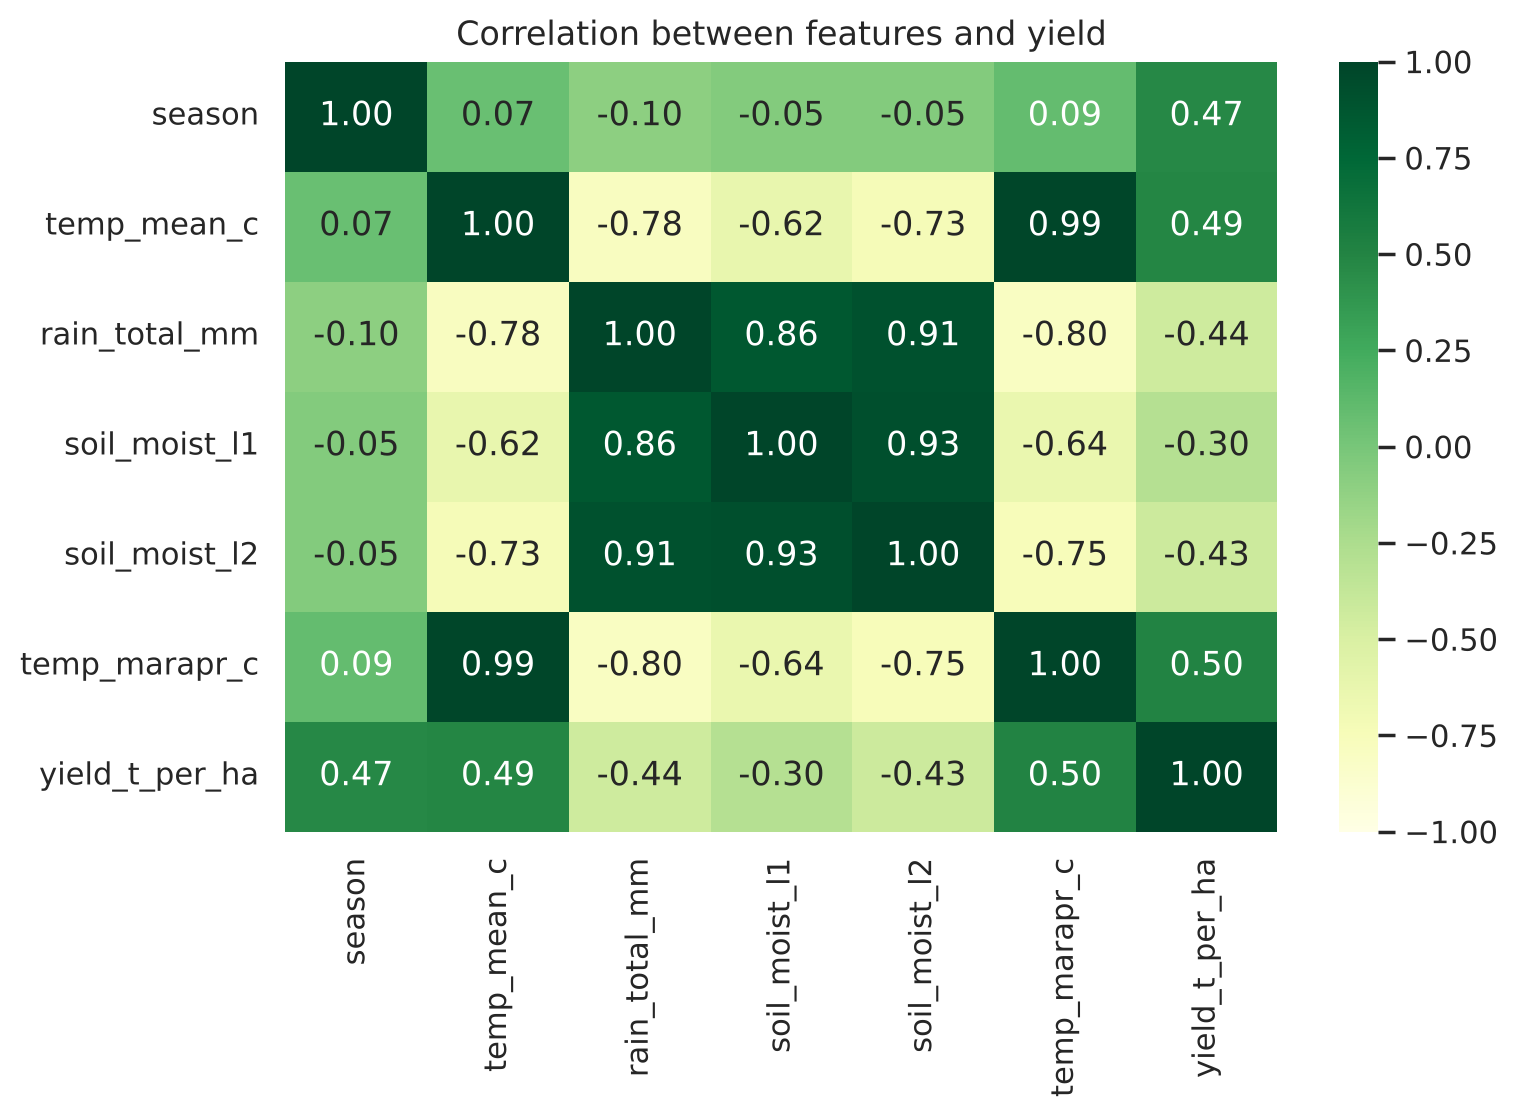

In [11]:
num_cols = ["season", "temp_mean_c", "rain_total_mm",
            "soil_moist_l1", "soil_moist_l2", "temp_marapr_c"]

plt.figure(figsize=(8, 5))
sns.heatmap(df_clean[num_cols + ["yield_t_per_ha"]].corr(),
            annot=True, fmt=".2f", cmap="YlGn", vmin=-1, vmax=1)
plt.title("Correlation between features and yield")
plt.show()

**Choosing features**
- **Target (what we predict):** `yield_t_per_ha`
- **Inputs:** the five climate columns, plus `season` (the year) and `province`
- **Left out on purpose:**
  - `production_000t`: it is yield × area, so it leaks the answer
  - `area_000ha`: not a climate factor, and the dashboard will not have it as an input
  - `district`, `district_code`, `crop`, `fy`: names and labels that add nothing new (the climate columns already describe each district's conditions)

Note: correlation is not cause. For example, rain looks negative partly because wetter districts are mountainous, which also tends to mean lower yields.

In [12]:
y = df_clean["yield_t_per_ha"]

province_dummies = pd.get_dummies(df_clean["province"], prefix="prov", dtype=int)

X = pd.concat([df_clean[num_cols], province_dummies], axis=1)

print("Input table shape:", X.shape)
print(list(X.columns))

Input table shape: (3591, 11)
['season', 'temp_mean_c', 'rain_total_mm', 'soil_moist_l1', 'soil_moist_l2', 'temp_marapr_c', 'prov_BALOCHISTAN', 'prov_ISLAMABAD CAPITAL TERRITORY', 'prov_KHYBER PAKHTUNKHWA', 'prov_PUNJAB', 'prov_SINDH']


**Splitting by time, not randomly**

We train on seasons up to **2015** and test on **2016 to 2024**. This mimics real forecasting: the model learns from the past and is judged on years it has never seen.

A random split would be too easy, because the model could peek at the neighbouring years of the same district.

**Heads-up:** yields rise over the decades, so test yields are higher than anything in the training years. Tree-based models cannot predict beyond the range they have seen, so we should expect them to under-predict the newest years. We will look for this when we evaluate.

In [13]:
is_train = df_clean["season"] <= 2015

X_train, X_test = X[is_train], X[~is_train]
y_train, y_test = y[is_train], y[~is_train]

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print(f"Train share: {len(X_train) / len(X) * 100:.1f}%")

Train rows: 2641 | Test rows: 950
Train share: 73.5%


In [14]:
print("Average yield, train years:", round(y_train.mean(), 2))
print("Average yield, test years: ", round(y_test.mean(), 2))

Average yield, train years: 1.9
Average yield, test years:  2.54


**Scaling**

Temperature is around 16 while rain is around 200, and Linear Regression can be thrown off by such different sizes. We rescale each numeric column to "average 0, typical spread 1".

Two rules:
- The scaler learns its averages from the **training data only** (so the test data stays truly unseen).
- Only Linear Regression needs the scaled version. Tree models (Random Forest, Gradient Boosting, XGBoost) do not care, so they will use the original numbers.

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train[num_cols])


X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print(X_train_scaled[num_cols].mean().round(2))

season          -0.0
temp_mean_c      0.0
rain_total_mm   -0.0
soil_moist_l1   -0.0
soil_moist_l2    0.0
temp_marapr_c    0.0
dtype: float64


In [16]:
df_clean.to_csv("../data/wheat_clean.csv", index=False)
print("Saved wheat_clean.csv with", df_clean.shape[0], "rows")

Saved wheat_clean.csv with 3591 rows


## 5. Climate Zones with K-Means
K-Means is *unsupervised*: it sorts districts into groups with similar climate, without being told the yield.
It helps us understand the data (which districts live in similar conditions) and gives us a "climate zone" label that we can optionally feed to the prediction models.

K-Means does not predict yield, so it is **not** part of the R², RMSE and MAE comparison. It is our explorer, not a contestant.

In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

climate_cols = ["temp_mean_c", "rain_total_mm", "soil_moist_l1", "soil_moist_l2", "temp_marapr_c"]
district_climate = df_clean[is_train].groupby("district")[climate_cols].mean()

Z = StandardScaler().fit_transform(district_climate)
print("Districts to cluster:", Z.shape[0])

Districts to cluster: 107


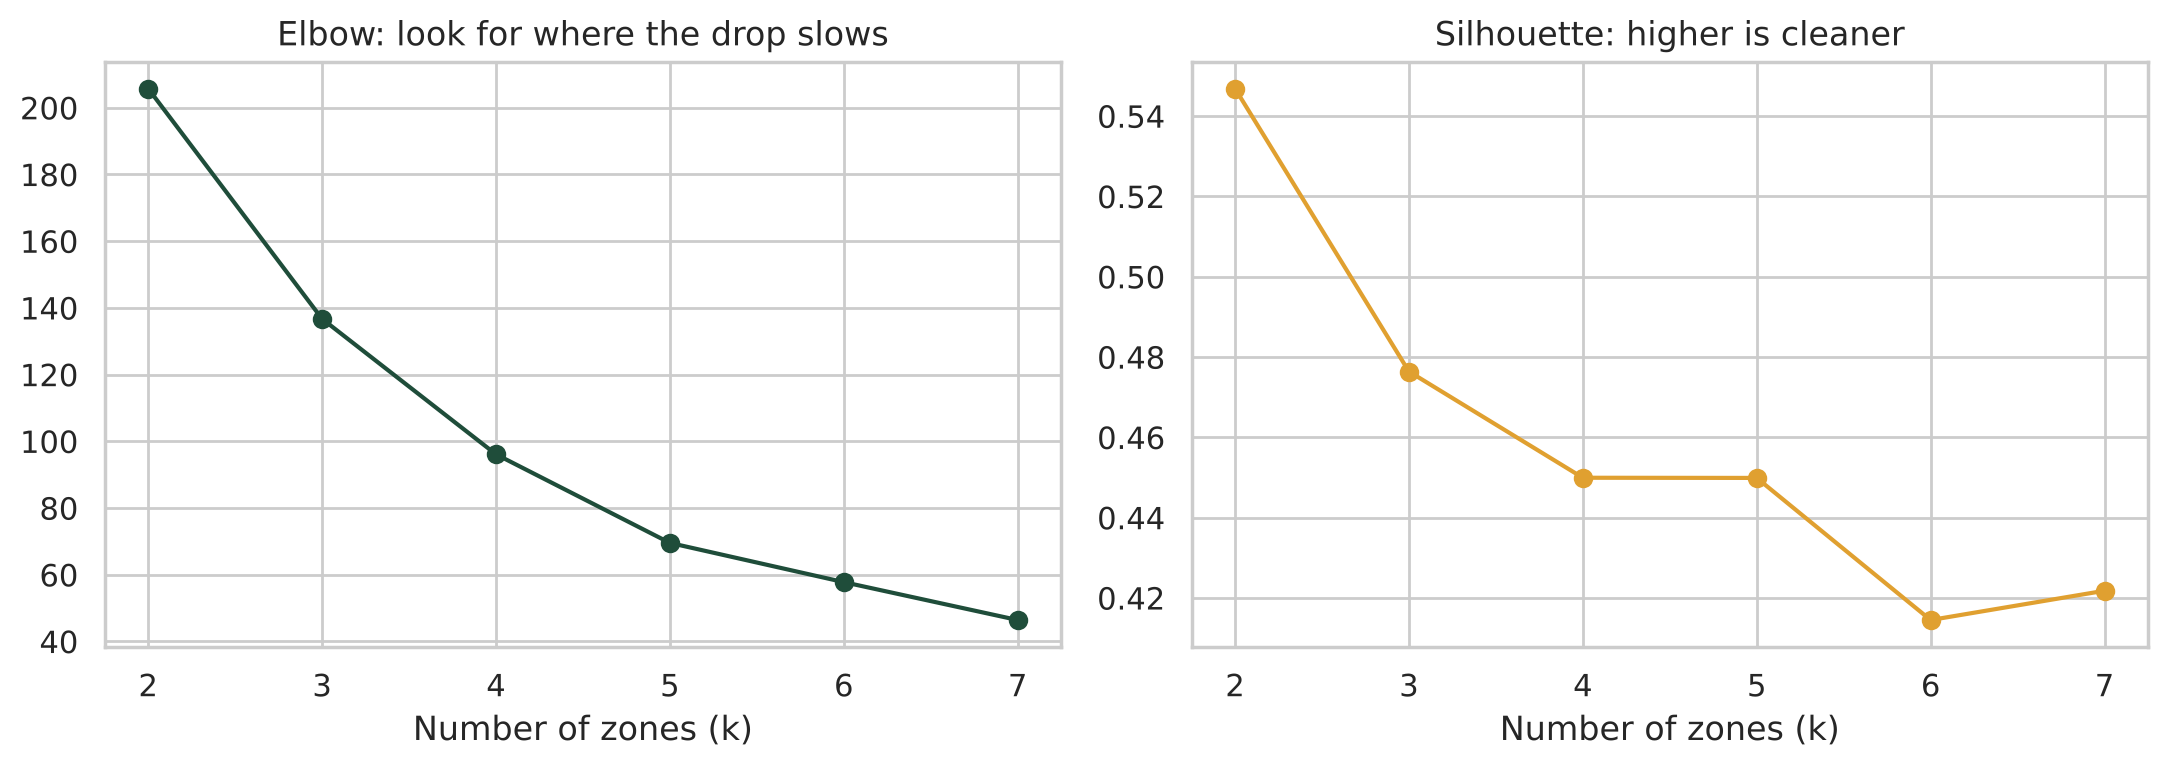

In [18]:
ks = range(2, 8)
inertia, silhouette = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inertia.append(km.inertia_)                      
    silhouette.append(silhouette_score(Z, km.labels_)) 

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, marker="o", color="#1F4D3A")
ax[0].set_title("Elbow: look for where the drop slows")
ax[0].set_xlabel("Number of zones (k)")
ax[1].plot(ks, silhouette, marker="o", color="#E0A030")
ax[1].set_title("Silhouette: higher is cleaner")
ax[1].set_xlabel("Number of zones (k)")
plt.tight_layout()
plt.show()

**Choosing k = 4**

The silhouette score is highest at 2 zones, but "wet vs dry" is too coarse to be useful. The elbow flattens around 4, and 4 zones have clear, explainable meanings. So we go with **4 zones**.

In [19]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Z)
district_climate["cluster"] = km.labels_

order = district_climate.groupby("cluster")["temp_mean_c"].mean().sort_values().index
relabel = {old: new for new, old in enumerate(order)}
district_climate["zone"] = district_climate["cluster"].map(relabel)

zone_names = {0: "Cold wet highlands", 1: "Cool wet foothills",
              2: "Moderate semi-arid", 3: "Hot dry plains"}
district_climate["zone_name"] = district_climate["zone"].map(zone_names)

print(district_climate.groupby("zone_name")[climate_cols].mean().round(2))
print()
print(district_climate["zone_name"].value_counts())

                    temp_mean_c  rain_total_mm  soil_moist_l1  soil_moist_l2  \
zone_name                                                                      
Cold wet highlands         1.83         771.21           0.35           0.35   
Cool wet foothills        12.42         394.81           0.27           0.28   
Hot dry plains            20.50          46.27           0.09           0.13   
Moderate semi-arid        14.10         180.33           0.15           0.19   

                    temp_marapr_c  
zone_name                          
Cold wet highlands           5.94  
Cool wet foothills          17.02  
Hot dry plains              26.01  
Moderate semi-arid          19.22  

zone_name
Hot dry plains        49
Moderate semi-arid    28
Cool wet foothills    25
Cold wet highlands     5
Name: count, dtype: int64


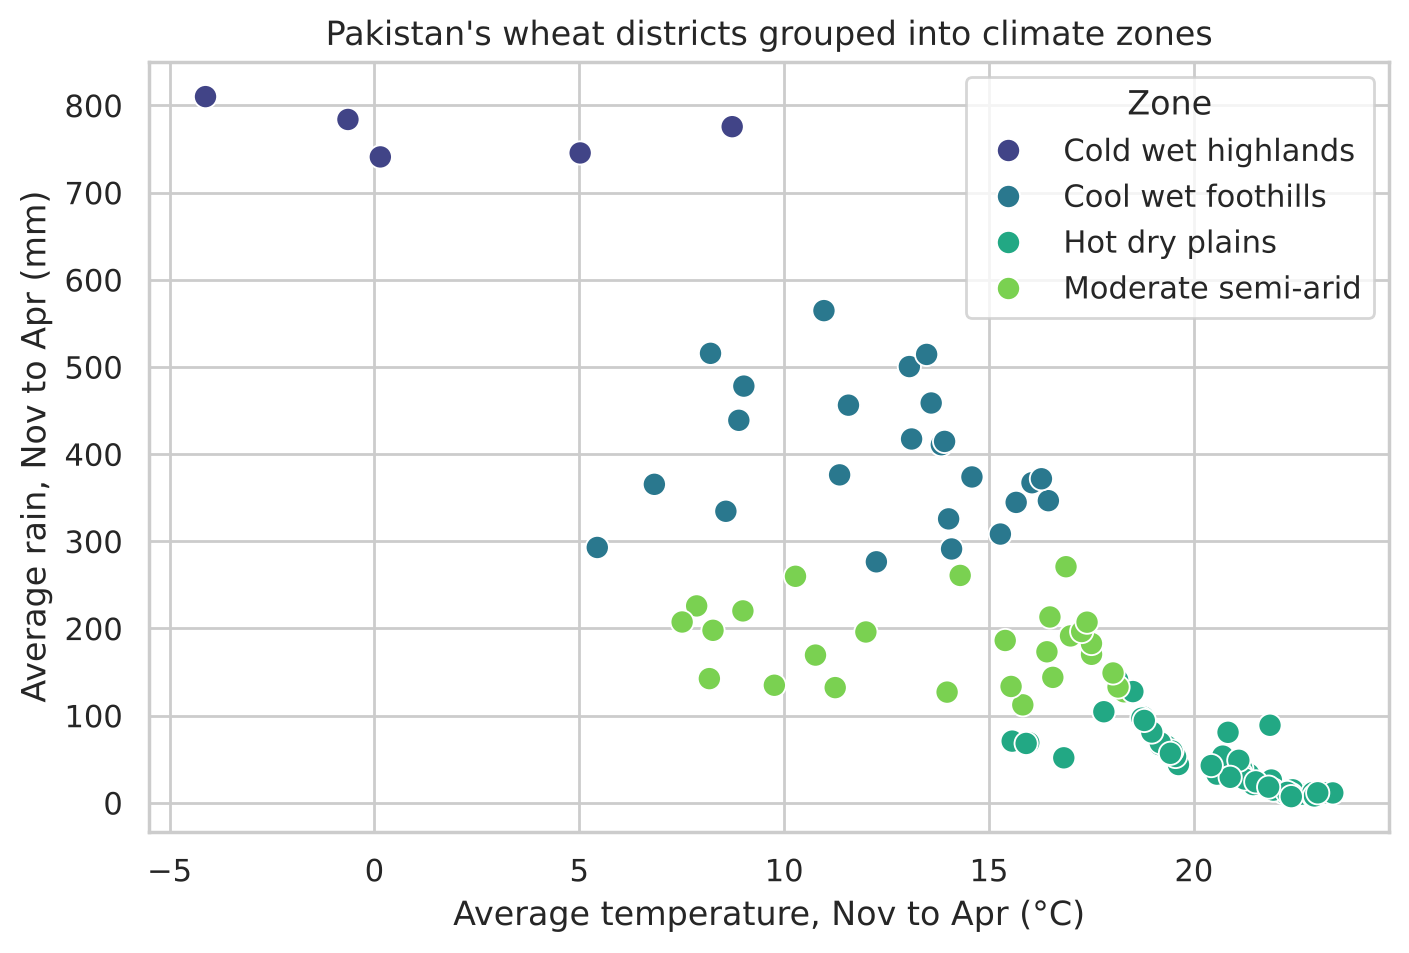

In [20]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=district_climate, x="temp_mean_c", y="rain_total_mm",
                hue="zone_name", s=70, palette="viridis")
plt.title("Pakistan's wheat districts grouped into climate zones")
plt.xlabel("Average temperature, Nov to Apr (°C)")
plt.ylabel("Average rain, Nov to Apr (mm)")
plt.legend(title="Zone")
plt.show()

In [21]:
df_clean["zone"] = df_clean["district"].map(district_climate["zone"])

print("Rows without a zone:", df_clean["zone"].isna().sum())
print()
print(df_clean.groupby(df_clean["zone"].map(zone_names))["yield_t_per_ha"].mean().round(2))

Rows without a zone: 0

zone
Cold wet highlands    1.49
Cool wet foothills    1.55
Hot dry plains        2.48
Moderate semi-arid    1.92
Name: yield_t_per_ha, dtype: float64


**Reading the result:** the hot dry plains (mostly irrigated canal land in Punjab and Sindh) have the highest yields, while the cold wet highlands have the lowest. Rain alone does not drive yield here: irrigation and growing conditions matter too.

**Decision:** we will create an extra version of our input tables that also contains the zone (as 0/1 columns). Later we will train on both versions and see whether the zone label actually helps.

In [22]:
zone_dummies = pd.get_dummies(df_clean["zone"], prefix="zone", dtype=int)

X_train_z = pd.concat([X_train, zone_dummies[is_train]], axis=1)
X_test_z = pd.concat([X_test, zone_dummies[~is_train]], axis=1)

X_train_scaled_z = pd.concat([X_train_scaled, zone_dummies[is_train]], axis=1)
X_test_scaled_z = pd.concat([X_test_scaled, zone_dummies[~is_train]], axis=1)

print("Inputs with zones:", X_train_z.shape, X_test_z.shape)

Inputs with zones: (2641, 15) (950, 15)


In [23]:
df_clean.to_csv("../data/wheat_clean.csv", index=False)

## 6. Training the Models
Teach each model to predict yield from the inputs, using only the training years (1981 to 2015).
Different models learn in different ways, so we compare them fairly: same data, same split, same scores.

| Model | How it thinks (plain English) |
|---|---|
| **Linear Regression** | Draws the best straight-line relationship. Our simple baseline: if the fancy models can't beat it, they aren't worth it. |
| **Random Forest** | Builds many decision trees on random slices of the data and averages their answers. |
| **Gradient Boosting** | Builds small trees one after another, each fixing the mistakes of the previous ones. |
| **XGBoost** | A fast, polished version of gradient boosting. |

We also include a "guess the average" predictor as a floor: any real model must beat it.

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

def make_models():
    return {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(
            n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42),
        "XGBoost": XGBRegressor(
            n_estimators=300, learning_rate=0.05, max_depth=4,
            subsample=0.8, random_state=42, n_jobs=-1),
    }

In [25]:
import time

models_base, preds_base = {}, {}

for name, model in make_models().items():
    if name == "Linear Regression":
        Xtr, Xte = X_train_scaled, X_test_scaled
    else:
        Xtr, Xte = X_train, X_test

    start = time.time()
    model.fit(Xtr, y_train)                 # learn from the training years
    preds_base[name] = model.predict(Xte)   # predict the unseen test years
    models_base[name] = model
    print(f"{name:20s} trained in {time.time() - start:.2f}s")

Linear Regression    trained in 0.00s


Random Forest        trained in 2.11s


Gradient Boosting    trained in 1.19s
XGBoost              trained in 0.14s


In [26]:
# Same again, but with the climate-zone columns added to the inputs
models_zone, preds_zone = {}, {}

for name, model in make_models().items():
    if name == "Linear Regression":
        Xtr, Xte = X_train_scaled_z, X_test_scaled_z
    else:
        Xtr, Xte = X_train_z, X_test_z

    start = time.time()
    model.fit(Xtr, y_train)
    preds_zone[name] = model.predict(Xte)
    models_zone[name] = model
    print(f"{name:20s} (with zones) trained in {time.time() - start:.2f}s")

Linear Regression    (with zones) trained in 0.00s


Random Forest        (with zones) trained in 2.20s


Gradient Boosting    (with zones) trained in 1.23s
XGBoost              (with zones) trained in 0.14s


In [27]:
baseline_pred = np.full(len(y_test), y_train.mean())
print("Floor model predicts", round(y_train.mean(), 2), "t/ha for every row")

Floor model predicts 1.9 t/ha for every row


## 6.1 Checking Model Size
The dashboard runs in a web browser, so anything we ship must be small. Let us measure what each trained model weighs on disk.

In [28]:
import os
import joblib

os.makedirs("../models", exist_ok=True)   # a folder to hold the saved models

for name, model in models_base.items():
    path = f"../models/{name.replace(' ', '_').lower()}.pkl"
    joblib.dump(model, path)                       # save the trained model to disk
    size_mb = os.path.getsize(path) / 1_000_000    # bytes -> megabytes
    print(f"{name:20s} {size_mb:8.3f} MB")

Linear Regression       0.001 MB


Random Forest          20.072 MB
Gradient Boosting       0.400 MB
XGBoost                 0.509 MB


## 7. Evaluating the Models
Score every model on the test years (2016 to 2024), data none of them saw while learning.
A model that looks great on data it practised on proves nothing. The test years are the real exam.

**The three scores**
- **R² (R-squared):** how much of the ups and downs in yield the model explains. 1 = perfect, 0 = no better than always guessing the average, below 0 = worse than guessing.
- **RMSE:** the typical size of the error, in tonnes per hectare. It punishes big misses extra hard. Lower is better.
- **MAE:** the average size of the error, in tonnes per hectare. Easy to explain: "on average we are off by this much". Lower is better.

In [29]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def scores(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "MAE": mean_absolute_error(y_true, y_pred)}

rows = {"Floor (always the average)": scores(y_test, baseline_pred)}
for name, pred in preds_base.items():
    rows[name] = scores(y_test, pred)
for name, pred in preds_zone.items():
    rows[name + " + zones"] = scores(y_test, pred)

results = pd.DataFrame(rows).T.round(3).sort_values("R2", ascending=False)
results

,R2,RMSE,MAE
XGBoost + zones,0.694,0.461,0.365
XGBoost,0.689,0.464,0.364
Gradient Boosting + zones,0.678,0.472,0.374
Random Forest + zones,0.669,0.479,0.380
Gradient Boosting,0.668,0.480,0.378
Random Forest,0.660,0.486,0.383
Linear Regression + zones,0.570,0.546,0.444
Linear Regression,0.520,0.577,0.470
Floor (always the average),-0.585,1.048,0.851


In [30]:
rows = {}
for name, pred in preds_base.items():
    pct_error = (pred - y_test).abs() / y_test        
    mape = pct_error.mean() * 100                     
    rows[name] = {
        "Avg % error (MAPE)": mape,
        "Accuracy % (100 - MAPE)": 100 - mape,
        "Within 20% of real": (pct_error <= 0.20).mean() * 100,
        "Within 0.5 t/ha": ((pred - y_test).abs() <= 0.5).mean() * 100,
    }

pd.DataFrame(rows).T.round(1).sort_values("Accuracy % (100 - MAPE)", ascending=False)

,Avg % error (MAPE),Accuracy % (100 - MAPE),Within 20% of real,Within 0.5 t/ha
XGBoost,17.6,82.4,72.7,71.2
Gradient Boosting,18.3,81.7,72.2,69.7
Random Forest,18.5,81.5,71.2,68.3
Linear Regression,25.0,75.0,63.8,60.3


**Reading the table**
- Every real model beats the floor by a wide margin, so the climate and location inputs genuinely carry information.
- The boosted trees (XGBoost, Gradient Boosting) lead, Random Forest is close behind, and Linear Regression trails: the climate-to-yield relationship is not a straight line.
- Adding climate zones helps Linear Regression noticeably but the tree models only slightly (about +0.005 R²). Trees can already work out regional differences from province and climate, so the extra complexity is not worth it.

**Decision:** the final model is **XGBoost on the base inputs** (no zones). It is accurate, tiny on disk (about 0.5 MB), and uses only inputs the dashboard can ask for.

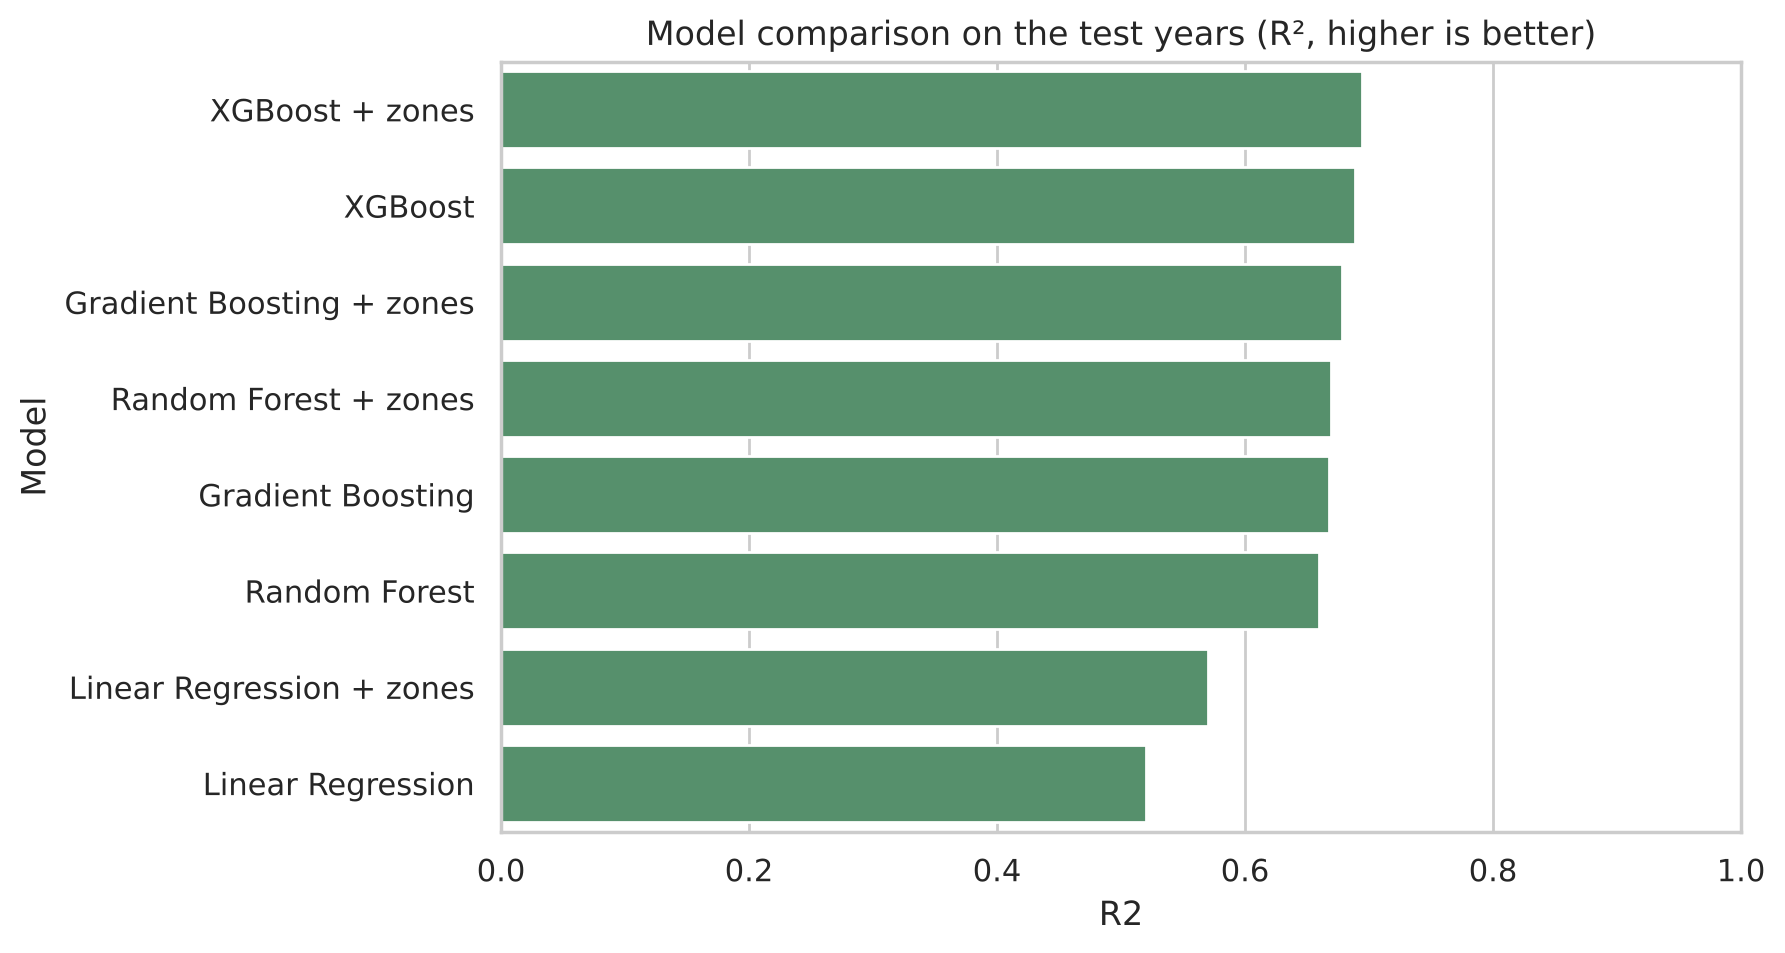

In [31]:
plot_df = results.drop(index="Floor (always the average)").reset_index()
plot_df = plot_df.rename(columns={"index": "Model"})

plt.figure(figsize=(8, 5))
sns.barplot(data=plot_df, x="R2", y="Model", color="#4C9A6A")
plt.title("Model comparison on the test years (R², higher is better)")
plt.xlim(0, 1)
plt.show()

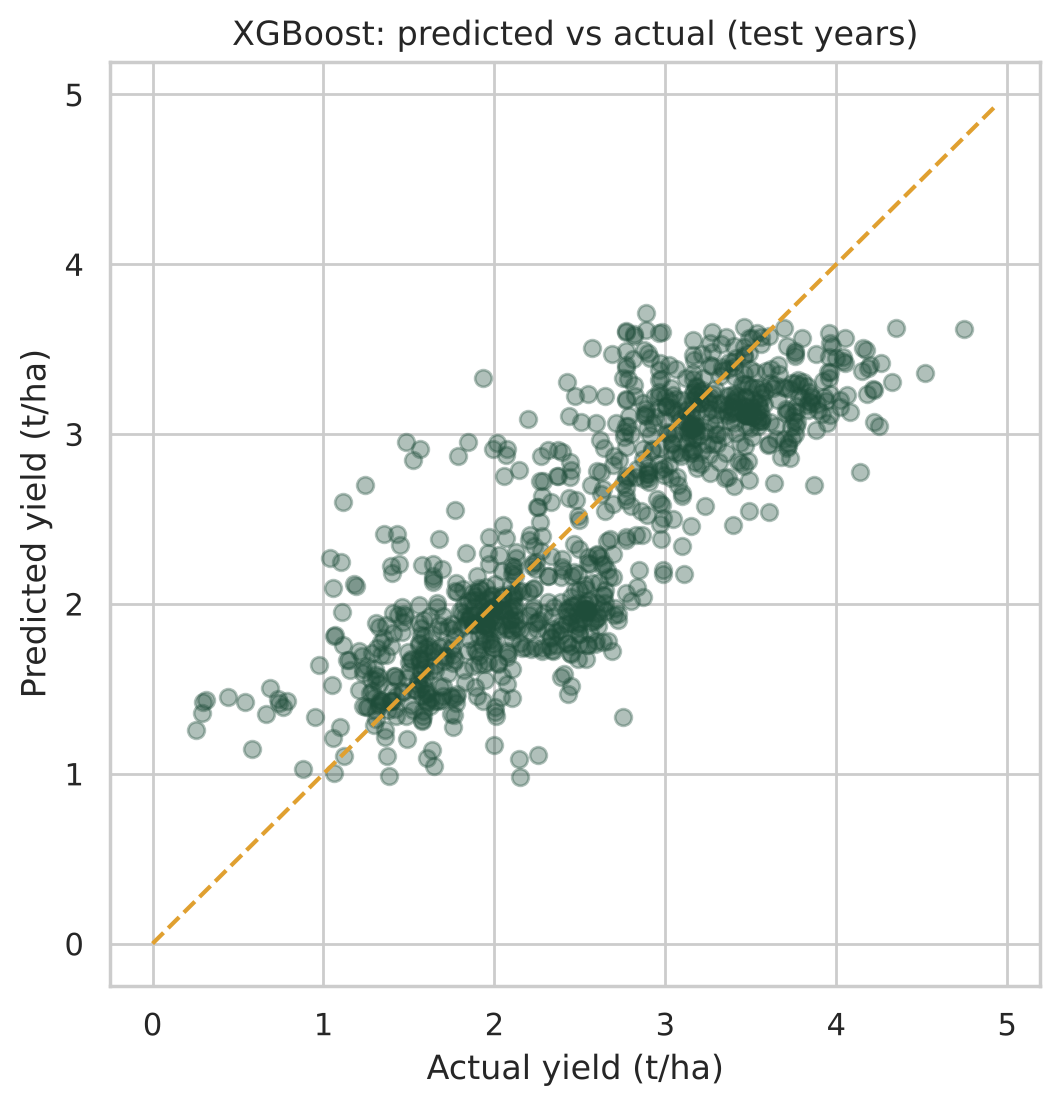

In [32]:
final_pred = preds_base["XGBoost"]

plt.figure(figsize=(6, 6))
plt.scatter(y_test, final_pred, alpha=0.35, color="#1F4D3A")
limits = [0, max(y_test.max(), final_pred.max()) + 0.2]
plt.plot(limits, limits, "--", color="#E0A030")    
plt.xlabel("Actual yield (t/ha)")
plt.ylabel("Predicted yield (t/ha)")
plt.title("XGBoost: predicted vs actual (test years)")
plt.show()

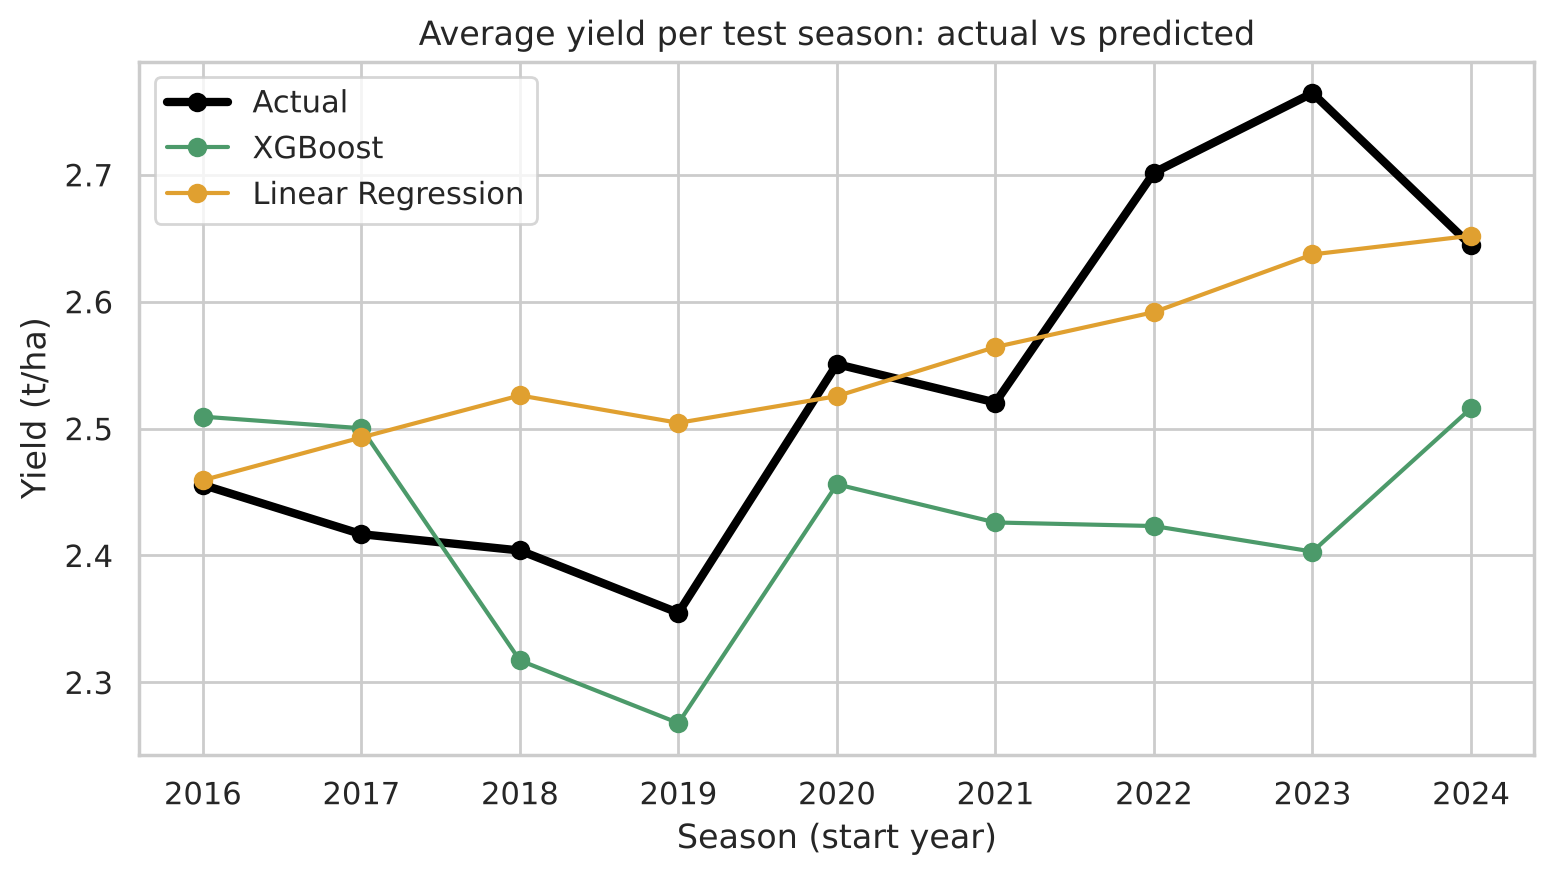

Average error (predicted minus actual):
XGBoost:           -0.111
Linear Regression: 0.015


In [33]:
view = df_clean[~is_train].copy()
view["XGBoost"] = preds_base["XGBoost"]
view["Linear Regression"] = preds_base["Linear Regression"]

yearly = view.groupby("season")[["yield_t_per_ha", "XGBoost", "Linear Regression"]].mean()

plt.figure(figsize=(9, 4.5))
plt.plot(yearly.index, yearly["yield_t_per_ha"], marker="o", lw=3, color="black", label="Actual")
plt.plot(yearly.index, yearly["XGBoost"], marker="o", color="#4C9A6A", label="XGBoost")
plt.plot(yearly.index, yearly["Linear Regression"], marker="o", color="#E0A030", label="Linear Regression")
plt.title("Average yield per test season: actual vs predicted")
plt.xlabel("Season (start year)")
plt.ylabel("Yield (t/ha)")
plt.legend()
plt.show()

print("Average error (predicted minus actual):")
print("XGBoost:          ", round((view["XGBoost"] - view["yield_t_per_ha"]).mean(), 3))
print("Linear Regression:", round((view["Linear Regression"] - view["yield_t_per_ha"]).mean(), 3))

**The trend limitation**

XGBoost tracks the early test years well but **under-predicts 2022 and 2023** (by about 0.3 t/ha) because those years have higher yields than anything it saw in training, and tree models cannot go beyond their training range. Linear Regression follows the upward trend better on average, but it is less accurate district by district.

This is a limitation to report: the model is strongest at explaining *differences between places and weather*, and weaker at predicting *future technology gains*. Possible fixes (future work): predict yield *relative to the district's recent average*, or keep retraining as new years arrive.

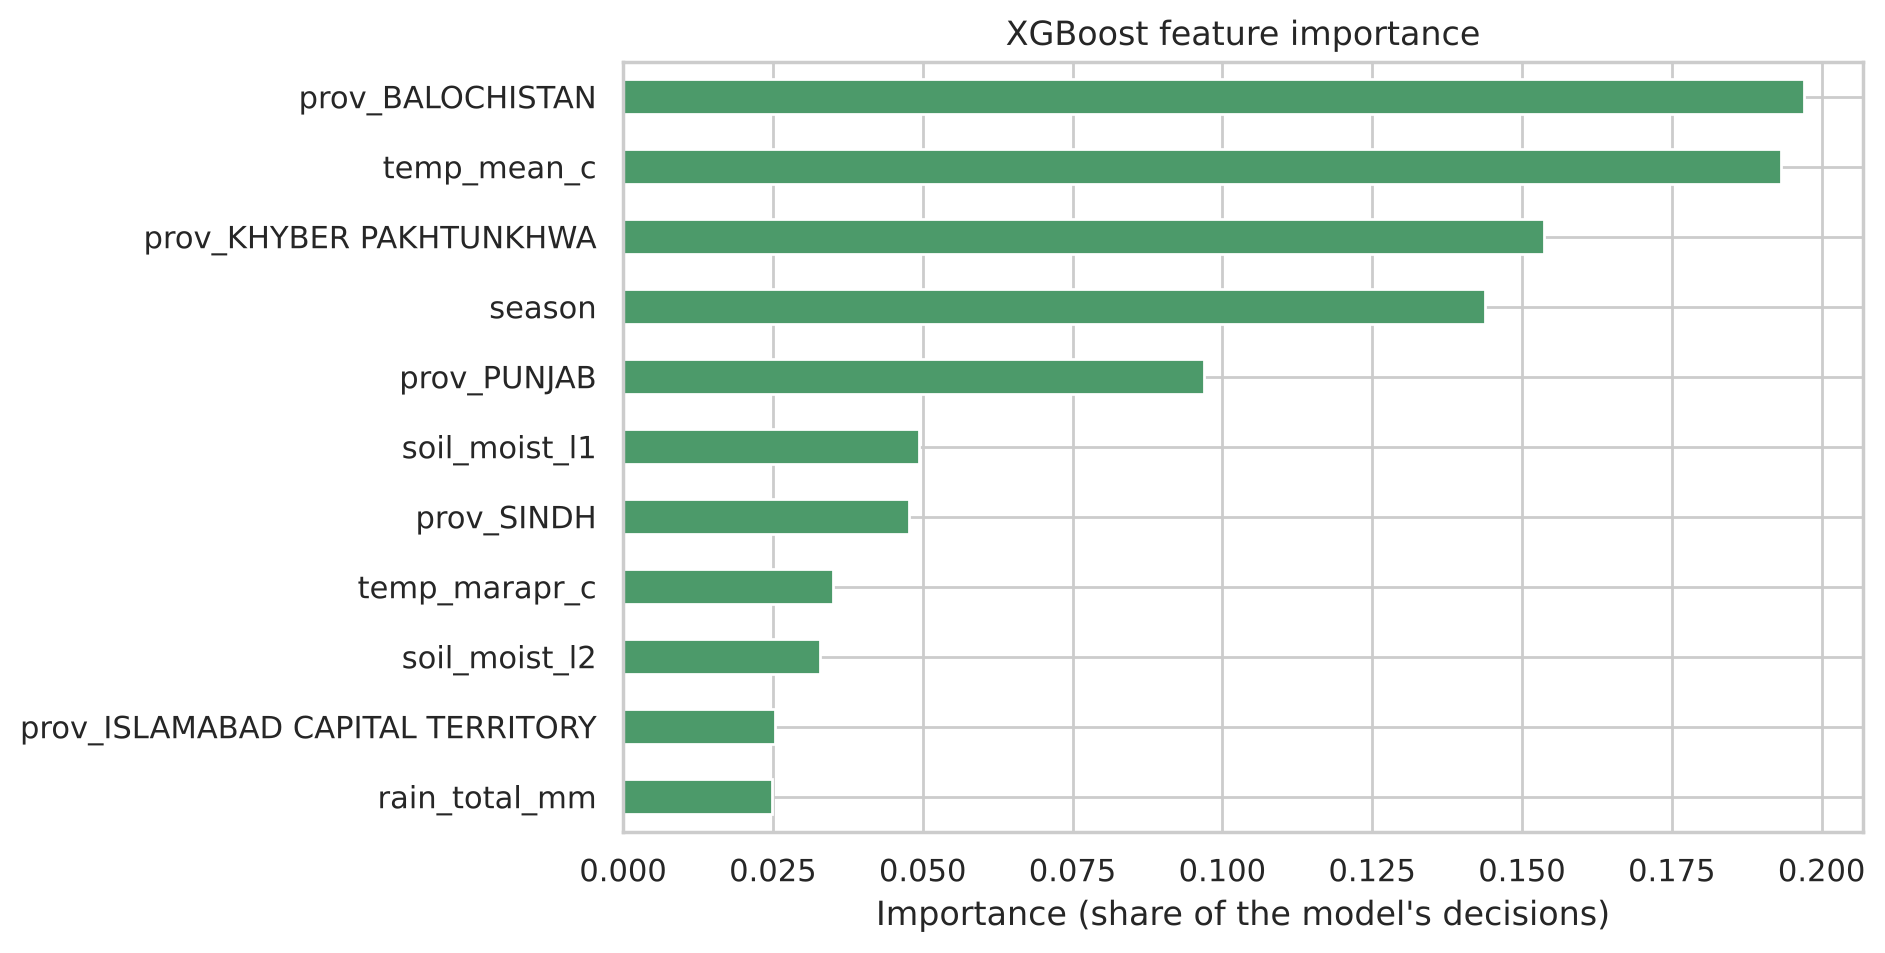

In [34]:
importance = pd.Series(models_base["XGBoost"].feature_importances_,
                       index=X_train.columns).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="#4C9A6A")
plt.title("XGBoost feature importance")
plt.xlabel("Importance (share of the model's decisions)")
plt.show()

**What drives the predictions?**
Location (province) and average season temperature matter most, followed by the year (technology trend) and soil moisture. Rainfall on its own matters less than expected: much of Pakistan's wheat is irrigated, so rain is not the main limit on yield there.

Importance shows what the model *uses*, not what *causes* yield. Wetter districts also tend to be mountainous, so rain partly stands in for location.

## 8. Exporting for the Dashboard
Save the final model and some history as small JSON files that a web page can read.
A browser cannot run Python or load a `.pkl` file. But an XGBoost model is just 300 small decision trees, and a few lines of JavaScript can walk through them and add up the results.

**Files we create**
- `model.json`: the trees, the input order, and sensible slider ranges per province
- `history.json`: past yields per province, test-year predictions, the model comparison table and feature importance (for the dashboard's charts)

**Important:** the scores above come from the model trained on 1981 to 2015. For the dashboard we retrain the same model on *all* years, so it also learns from 2016 to 2024.

In [35]:
import json
from xgboost import XGBRegressor

final_model = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                           subsample=0.8, random_state=42, n_jobs=-1)
final_model.fit(X, y)

os.makedirs("../docs/data", exist_ok=True) 
print("Final model trained on", len(X), "rows")

Final model trained on 3591 rows


In [36]:
# --- Pull the trees out of XGBoost and shrink them into a compact format ---
booster = final_model.get_booster()
config = json.loads(booster.save_config())
# The model's starting guess, which every tree's answer gets added to
base_score = float(str(config["learner"]["learner_model_param"]["base_score"]).strip("[]"))

features = list(X.columns)
position = {name: i for i, name in enumerate(features)}   # feature name -> column number

def compact(node):
    # A leaf holds a number. A split says: "if feature f < t go YES, else go NO".
    if "leaf" in node:
        return {"v": round(node["leaf"], 6)}
    kids = {c["nodeid"]: c for c in node["children"]}
    return {"f": position[node["split"]], "t": node["split_condition"],
            "y": compact(kids[node["yes"]]), "n": compact(kids[node["no"]])}

trees = [compact(json.loads(t)) for t in booster.get_dump(dump_format="json")]

# --- Slider ranges: each province's min / average / max for the climate inputs ---
climate_features = ["temp_mean_c", "rain_total_mm", "soil_moist_l1", "soil_moist_l2", "temp_marapr_c"]
province_climate = {}
for prov, group in df_clean.groupby("province"):
    province_climate[prov] = {c: [round(float(group[c].min()), 3),
                                  round(float(group[c].mean()), 3),
                                  round(float(group[c].max()), 3)]
                              for c in climate_features}

model_json = {
    "features": features,
    "base_score": base_score,
    "province_features": {p: "prov_" + p for p in sorted(df_clean["province"].unique())},
    "season_range": [int(df_clean["season"].min()), int(df_clean["season"].max())],
    "province_climate": province_climate,
    "trees": trees,
}
with open("../docs/data/model.json", "w") as f:
    json.dump(model_json, f, separators=(",", ":"))   # compact, no extra spaces

print("Trees exported:", len(trees))

Trees exported: 300


In [37]:
# --- Safety check: does the "JavaScript way" give the same answers as XGBoost? ---
def predict_like_js(row):
    row = row.astype(np.float32)        # XGBoost uses 32-bit numbers (JS: Math.fround)
    total = base_score                  # start from the base guess
    for tree in trees:
        node = tree
        while "v" not in node:          # walk down until we reach a leaf
            node = node["y"] if row[node["f"]] < node["t"] else node["n"]
        total += node["v"]              # add that tree's answer
    return total

js_style = np.array([predict_like_js(r) for r in X.values])
print("Biggest difference vs XGBoost:", np.abs(js_style - final_model.predict(X)).max())

Biggest difference vs XGBoost: 1.4176094055518007e-05


In [38]:
# --- history.json: everything the dashboard's charts need ---
by_province = df_clean.groupby(["province", "season"])["yield_t_per_ha"].mean().round(3).reset_index()
history = {"yield_by_province": {
    p: {"seasons": g["season"].tolist(), "yield": g["yield_t_per_ha"].tolist()}
    for p, g in by_province.groupby("province")}}

# Actual vs predicted for the test years (from the train-only XGBoost)
test_view = df_clean[~is_train].copy()
test_view["pred"] = preds_base["XGBoost"]
t = test_view.groupby("season")[["yield_t_per_ha", "pred"]].mean().round(3)
history["test_years"] = {"seasons": t.index.tolist(),
                         "actual": t["yield_t_per_ha"].tolist(),
                         "predicted": t["pred"].tolist()}

# The model comparison table and feature importance
history["model_comparison"] = results.reset_index().rename(columns={"index": "model"}).to_dict(orient="records")
importance = pd.Series(models_base["XGBoost"].feature_importances_,
                       index=X_train.columns).sort_values(ascending=False)
history["feature_importance"] = {k: round(float(v), 4) for k, v in importance.items()}

with open("../docs/data/history.json", "w") as f:
    json.dump(history, f)

In [39]:
# What did we make, and how big is it?
for fname in sorted(os.listdir("../docs/data")):
    size_kb = os.path.getsize(f"../docs/data/{fname}") / 1000
    print(f"{fname:15s} {size_kb:8.1f} KB")

history.json         4.1 KB
model.json         196.6 KB


## Summary
- **Data:** 3,591 district-season rows (107 districts, 1981 to 2024) built from Pakistan Bureau of Statistics yields, ERA5-Land climate and GADM district boundaries.
- **Best model:** XGBoost, R² ≈ 0.69, typically within about 14 to 18% of the real yield, and 7 in 10 predictions within ±0.5 t/ha.
- **Limitation:** tree models under-predict the newest high-yield years because they cannot predict beyond what they have seen.
- **Output:** `docs/data/model.json` and `history.json`, used by the web dashboard.